In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA = Path("/Users/partha/Documents/FX Carry/data")
FX_FILE = DATA / "currency_pairs.xlsx"


In [2]:
xls = pd.ExcelFile(FX_FILE)

In [3]:
cleaned = {}

for sheet in xls.sheet_names:
    df = pd.read_excel(FX_FILE, sheet_name=sheet)
    print(f"\n{sheet}: {df.columns.tolist()}")
    
    df = df.iloc[:, :2].copy()
    df.columns = ["date", "spot"]
    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )
    df["spot"] = pd.to_numeric(
        df["spot"],
        errors="coerce"
    )
    df = df.dropna(subset=["date", "spot"])
    df = df.drop_duplicates(
        subset="date",
        keep="last"
    )
    df = df.sort_values("date").reset_index(drop=True)
    cleaned[sheet] = df


usd_jpy: ['Date', 'Last Price']

usd_chf: ['Date', 'Last Price']

aud_usd: ['Date', 'Last Price']

nzd_usd: ['Date', 'Last Price']

usd_cad: ['Date', 'Last Price']

usd_nok: ['Date', 'Last Price']

gbp_usd: ['Date', 'Last Price']

eur_usd: ['Date', 'Last Price']


In [4]:
print("CLEANED FX DATASETS")
print("=" * 70)

for pair, df in cleaned.items():
    print(
        f"{pair:10s} | "
        f"rows={len(df):5d} | "
        f"start={df['date'].min().date()} | "
        f"end={df['date'].max().date()} | "
        f"missing={df['spot'].isna().sum()}"
    )

CLEANED FX DATASETS
usd_jpy    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
usd_chf    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
aud_usd    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
nzd_usd    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
usd_cad    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
usd_nok    | rows= 2608 | start=2016-08-17 | end=2026-08-17 | missing=0
gbp_usd    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0
eur_usd    | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0


In [5]:
FRD_FILE = DATA / "FRD_Export.xlsx"
xls_frd = pd.ExcelFile(FRD_FILE)
frd_sheets = [s for s in xls_frd.sheet_names if s != "Sheet9"]
for sheet in frd_sheets:
    df = pd.read_excel(FRD_FILE, sheet_name=sheet)
    print(sheet, df.columns.tolist())

eurusd ['Date', 'FRD']
usdjpy ['Date', 'FRD']
gbpusd ['Date', 'FRD']
usdcad ['Date', 'FRD']
audusd ['Date', 'FRD']
nzdusd ['Date', 'FRD']
usdnok ['Date', 'FRD']
usdchf ['Date', 'FRD']


In [6]:
frd_cleaned = {}
for sheet in frd_sheets:
    df = pd.read_excel(FRD_FILE, sheet_name=sheet)
    df = df.iloc[:, :2].copy()
    df.columns = ["date", "frd"]
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["frd"] = pd.to_numeric(df["frd"], errors="coerce")
    df = df.dropna(subset=["date", "frd"])
    df = df.drop_duplicates(subset="date", keep="last")
    df = df.sort_values("date").reset_index(drop=True)
    frd_cleaned[sheet] = df

for pair, df in frd_cleaned.items():
    print(f"{pair:7s} | rows={len(df):5d} | start={df['date'].min().date()} | end={df['date'].max().date()} | missing={df['frd'].isna().sum()}")

eurusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
usdjpy  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
gbpusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
usdcad  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
audusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
nzdusd  | rows= 2608 | start=2016-08-18 | end=2026-08-17 | missing=0
usdnok  | rows= 2603 | start=2016-08-18 | end=2026-08-17 | missing=0
usdchf  | rows= 2609 | start=2016-08-17 | end=2026-08-17 | missing=0


In [7]:
IR_FILE = "/Users/partha/Documents/FX Carry/data/interest rates.xlsx"

ir_sheets = pd.ExcelFile(IR_FILE).sheet_names

interest_rates = {}

for sheet in ir_sheets:
    df = pd.read_excel(IR_FILE, sheet_name=sheet)
    df = df.iloc[:, :2].copy()
    df.columns = ["date", "rate"]
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["rate"] = pd.to_numeric(df["rate"], errors="coerce")
    df = df.dropna(subset=["date", "rate"])
    df = df.drop_duplicates(subset="date", keep="last")
    df = df.sort_values("date").reset_index(drop=True)
    interest_rates[sheet] = df

for currency, df in interest_rates.items():
    print(f"{currency:7s} | rows={len(df):4d} | start={df['date'].min().date()} | end={df['date'].max().date()} | missing={df['rate'].isna().sum()}")

usd_ir  | rows=  47 | start=2015-03-31 | end=2026-09-08 | missing=0
eur_ir  | rows=  47 | start=2015-03-31 | end=2026-07-23 | missing=0
gbp_ir  | rows=  47 | start=2015-03-31 | end=2026-09-08 | missing=0
jpy_ir  | rows=  47 | start=2015-03-31 | end=2026-09-09 | missing=0
chf_ir  | rows=  47 | start=2015-03-31 | end=2026-09-09 | missing=0
nok_ir  | rows=  45 | start=2015-09-30 | end=2026-09-07 | missing=0
aud_ir  | rows=  47 | start=2015-03-31 | end=2026-08-11 | missing=0
nzd_ir  | rows=  47 | start=2015-03-31 | end=2026-09-02 | missing=0
cad_ir  | rows=  47 | start=2015-03-31 | end=2026-09-08 | missing=0


In [ ]:
rate_daily = pd.DataFrame({"date": cleaned["eur_usd"]["date"]})

for currency, df in interest_rates.items():
    rate_daily = pd.merge_asof(
        rate_daily.sort_values("date"),
        df[["date", "rate"]].sort_values("date"),
        on="date",
        direction="backward"
    )
    rate_daily = rate_daily.rename(columns={"rate": currency})

rate_daily = rate_daily[
    ["date", "usd_ir", "eur_ir", "gbp_ir", "jpy_ir", "chf_ir", "nok_ir", "aud_ir", "nzd_ir", "cad_ir"]
]

In [ ]:
currency_returns = pd.DataFrame({"date": cleaned["eur_usd"]["date"]})

currency_returns["EUR"] = cleaned["eur_usd"]["spot"].pct_change()
currency_returns["GBP"] = cleaned["gbp_usd"]["spot"].pct_change()
currency_returns["AUD"] = cleaned["aud_usd"]["spot"].pct_change()
currency_returns["NZD"] = cleaned["nzd_usd"]["spot"].pct_change()

currency_returns["JPY"] = cleaned["usd_jpy"]["spot"].shift(1) / cleaned["usd_jpy"]["spot"] - 1
currency_returns["CHF"] = cleaned["usd_chf"]["spot"].shift(1) / cleaned["usd_chf"]["spot"] - 1
currency_returns["CAD"] = cleaned["usd_cad"]["spot"].shift(1) / cleaned["usd_cad"]["spot"] - 1
currency_returns["NOK"] = cleaned["usd_nok"]["spot"].shift(1) / cleaned["usd_nok"]["spot"] - 1

currency_returns = currency_returns.dropna().reset_index(drop=True)


In [ ]:
currency_returns = currency_returns.merge(rate_daily, on="date", how="left")

currency_returns["EUR_diff"] = currency_returns["eur_ir"] - currency_returns["usd_ir"]
currency_returns["GBP_diff"] = currency_returns["gbp_ir"] - currency_returns["usd_ir"]
currency_returns["JPY_diff"] = currency_returns["jpy_ir"] - currency_returns["usd_ir"]
currency_returns["CHF_diff"] = currency_returns["chf_ir"] - currency_returns["usd_ir"]
currency_returns["NOK_diff"] = currency_returns["nok_ir"] - currency_returns["usd_ir"]
currency_returns["AUD_diff"] = currency_returns["aud_ir"] - currency_returns["usd_ir"]
currency_returns["NZD_diff"] = currency_returns["nzd_ir"] - currency_returns["usd_ir"]
currency_returns["CAD_diff"] = currency_returns["cad_ir"] - currency_returns["usd_ir"]


In [13]:
rank_cols = ["EUR_diff", "GBP_diff", "JPY_diff", "CHF_diff", "NOK_diff", "AUD_diff", "NZD_diff", "CAD_diff"]

for col in rank_cols:
    currency_returns[col] = currency_returns[col].shift(1)

currency_returns = currency_returns.dropna().reset_index(drop=True)


In [15]:
currency_carry = currency_returns[["date"]].copy()

currency_carry[["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]] = (
    currency_returns[rank_cols]
    .rename(columns={
        "EUR_diff": "EUR",
        "GBP_diff": "GBP",
        "JPY_diff": "JPY",
        "CHF_diff": "CHF",
        "NOK_diff": "NOK",
        "AUD_diff": "AUD",
        "NZD_diff": "NZD",
        "CAD_diff": "CAD"
    })
    .rank(axis=1, method="first", ascending=False)
)

print(currency_carry.head())

        date  EUR  GBP  JPY  CHF  NOK  AUD  NZD  CAD
0 2016-08-22  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
1 2016-08-23  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
2 2016-08-24  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
3 2016-08-25  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
4 2016-08-26  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0


In [17]:
currency_returns["month"] = currency_returns["date"].dt.to_period("M")
currency_carry["month"] = currency_carry["date"].dt.to_period("M")

formation_dates = currency_returns.groupby("month")["date"].min().reset_index()

print(formation_dates.head(10))
print()
print(formation_dates.tail(10))
print()
print("Number of formation months:", len(formation_dates))


     month       date
0  2016-08 2016-08-22
1  2016-09 2016-09-01
2  2016-10 2016-10-03
3  2016-11 2016-11-01
4  2016-12 2016-12-01
5  2017-01 2017-01-02
6  2017-02 2017-02-01
7  2017-03 2017-03-01
8  2017-04 2017-04-03
9  2017-05 2017-05-01

       month       date
111  2025-11 2025-11-03
112  2025-12 2025-12-01
113  2026-01 2026-01-01
114  2026-02 2026-02-02
115  2026-03 2026-03-02
116  2026-04 2026-04-01
117  2026-05 2026-05-01
118  2026-06 2026-06-01
119  2026-07 2026-07-01
120  2026-08 2026-08-03

Number of formation months: 121


In [18]:
monthly_ranks = currency_carry.groupby("month").first().reset_index()

monthly_ranks = monthly_ranks[
    ["month", "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
]

print(monthly_ranks.head())
print()
print(monthly_ranks.tail())

     month  EUR  GBP  JPY  CHF  NOK  AUD  NZD  CAD
0  2016-08  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
1  2016-09  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
2  2016-10  7.0  3.0  6.0  8.0  4.0  2.0  1.0  5.0
3  2016-11  7.0  5.0  6.0  8.0  3.0  2.0  1.0  4.0
4  2016-12  7.0  5.0  6.0  8.0  3.0  2.0  1.0  4.0

       month  EUR  GBP  JPY  CHF  NOK  AUD  NZD  CAD
116  2026-04  6.0  2.0  7.0  8.0  1.0  3.0  4.0  5.0
117  2026-05  6.0  3.0  7.0  8.0  2.0  1.0  4.0  5.0
118  2026-06  6.0  3.0  7.0  8.0  2.0  1.0  4.0  5.0
119  2026-07  6.0  3.0  7.0  8.0  2.0  1.0  4.0  5.0
120  2026-08  4.0  3.0  7.0  8.0  2.0  1.0  5.0  6.0


In [22]:
monthly_positions = monthly_ranks.copy()

rank_data = monthly_ranks[["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]]

monthly_positions["long_1"] = rank_data.idxmin(axis=1)
monthly_positions["long_2"] = rank_data.apply(lambda x: x.sort_values().index[1], axis=1)
monthly_positions["short_1"] = rank_data.idxmax(axis=1)
monthly_positions["short_2"] = rank_data.apply(lambda x: x.sort_values(ascending=False).index[1], axis=1)

print(monthly_positions[["month", "long_1", "long_2", "short_1", "short_2"]].head(12))

print(monthly_positions[["month", "long_1", "long_2", "short_1", "short_2"]].tail(12))
print()
print("Formation months:", len(monthly_positions))
print("Start:", monthly_positions["month"].min())
print("End:", monthly_positions["month"].max())

      month long_1 long_2 short_1 short_2
0   2016-08    NZD    AUD     CHF     EUR
1   2016-09    NZD    AUD     CHF     EUR
2   2016-10    NZD    AUD     CHF     EUR
3   2016-11    NZD    AUD     CHF     EUR
4   2016-12    NZD    AUD     CHF     EUR
5   2017-01    NZD    AUD     CHF     EUR
6   2017-02    NZD    AUD     CHF     EUR
7   2017-03    NZD    AUD     CHF     EUR
8   2017-04    NZD    AUD     CHF     EUR
9   2017-05    NZD    AUD     CHF     EUR
10  2017-06    NZD    AUD     CHF     EUR
11  2017-07    NZD    AUD     CHF     EUR
       month long_1 long_2 short_1 short_2
109  2025-09    GBP    NOK     CHF     JPY
110  2025-10    GBP    NOK     CHF     JPY
111  2025-11    GBP    NOK     CHF     JPY
112  2025-12    GBP    NOK     CHF     JPY
113  2026-01    GBP    NOK     CHF     JPY
114  2026-02    NOK    GBP     CHF     JPY
115  2026-03    NOK    GBP     CHF     JPY
116  2026-04    NOK    GBP     CHF     JPY
117  2026-05    AUD    NOK     CHF     JPY
118  2026-06    AUD    N

In [23]:
currency_returns["month"] = currency_returns["date"].dt.to_period("M")

monthly_returns = currency_returns.groupby("month")[["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]].apply(
    lambda x: (1 + x).prod() - 1
).reset_index()

monthly_returns.columns = ["month", "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]

print(monthly_returns.head())
print()
print(monthly_returns.tail())
print()
print("Monthly observations:", len(monthly_returns))

     month       EUR       GBP       JPY       CHF       NOK       AUD  \
0  2016-08 -0.014746  0.004818 -0.031035 -0.023783 -0.013064 -0.014422   
1  2016-09  0.006901 -0.012635  0.020523  0.012868  0.043008  0.019556   
2  2016-10 -0.022608 -0.056275 -0.033104 -0.017796 -0.033295 -0.007176   
3  2016-11 -0.035698  0.021565 -0.084222 -0.027819 -0.031121 -0.029439   
4  2016-12 -0.006800 -0.013274 -0.021375 -0.001668 -0.013390 -0.023968   

        NZD       CAD  
0 -0.003025 -0.017856  
1  0.004966 -0.001676  
2 -0.018529 -0.021031  
3 -0.009509 -0.002084  
4 -0.021036 -0.000298  

       month       EUR       GBP       JPY       CHF       NOK       AUD  \
116  2026-04  0.015407  0.028502  0.013602  0.023164  0.044842  0.043623   
117  2026-05 -0.006138 -0.010879 -0.016827  0.000512  0.002308 -0.002222   
118  2026-06 -0.020328 -0.014417 -0.020178 -0.033894 -0.064709 -0.037022   
119  2026-07  0.009193  0.016664  0.032719  0.001115  0.038959  0.014453   
120  2026-08  0.003730  0.0040

In [24]:
monthly_positions["holding_month"] = monthly_positions["month"] + 1

backtest = monthly_positions.merge(
    monthly_returns,
    left_on="holding_month",
    right_on="month",
    how="inner"
)

backtest = backtest.drop(columns=["month_y"]).rename(columns={"month_x": "formation_month"})

print(backtest[["formation_month", "holding_month", "long_1", "long_2", "short_1", "short_2"]].head(12))
print()
print(backtest[["formation_month", "holding_month", "long_1", "long_2", "short_1", "short_2"]].tail(12))
print()
print("Backtest months:", len(backtest))

   formation_month holding_month long_1 long_2 short_1 short_2
0          2016-08       2016-09    NZD    AUD     CHF     EUR
1          2016-09       2016-10    NZD    AUD     CHF     EUR
2          2016-10       2016-11    NZD    AUD     CHF     EUR
3          2016-11       2016-12    NZD    AUD     CHF     EUR
4          2016-12       2017-01    NZD    AUD     CHF     EUR
5          2017-01       2017-02    NZD    AUD     CHF     EUR
6          2017-02       2017-03    NZD    AUD     CHF     EUR
7          2017-03       2017-04    NZD    AUD     CHF     EUR
8          2017-04       2017-05    NZD    AUD     CHF     EUR
9          2017-05       2017-06    NZD    AUD     CHF     EUR
10         2017-06       2017-07    NZD    AUD     CHF     EUR
11         2017-07       2017-08    NZD    AUD     CHF     EUR

    formation_month holding_month long_1 long_2 short_1 short_2
108         2025-08       2025-09    GBP    NOK     CHF     JPY
109         2025-09       2025-10    GBP    NOK     

In [26]:
backtest["long_fx"] = [
    (monthly_returns.loc[monthly_returns["month"] == row["holding_month"], row["long_1"]].iloc[0] +
     monthly_returns.loc[monthly_returns["month"] == row["holding_month"], row["long_2"]].iloc[0]) / 2
    for _, row in backtest.iterrows()
]

backtest["short_fx"] = [
    (monthly_returns.loc[monthly_returns["month"] == row["holding_month"], row["short_1"]].iloc[0] +
     monthly_returns.loc[monthly_returns["month"] == row["holding_month"], row["short_2"]].iloc[0]) / 2
    for _, row in backtest.iterrows()
]

backtest["long_short_fx"] = backtest["long_fx"] - backtest["short_fx"]

print(backtest[[
    "formation_month",
    "holding_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "long_fx",
    "short_fx",
    "long_short_fx"
]].head(12))

   formation_month holding_month long_1 long_2 short_1 short_2   long_fx  \
0          2016-08       2016-09    NZD    AUD     CHF     EUR  0.012261   
1          2016-09       2016-10    NZD    AUD     CHF     EUR -0.012853   
2          2016-10       2016-11    NZD    AUD     CHF     EUR -0.019474   
3          2016-11       2016-12    NZD    AUD     CHF     EUR -0.022502   
4          2016-12       2017-01    NZD    AUD     CHF     EUR  0.053408   
5          2017-01       2017-02    NZD    AUD     CHF     EUR -0.003459   
6          2017-02       2017-03    NZD    AUD     CHF     EUR -0.014759   
7          2017-03       2017-04    NZD    AUD     CHF     EUR -0.019232   
8          2017-04       2017-05    NZD    AUD     CHF     EUR  0.012075   
9          2017-05       2017-06    NZD    AUD     CHF     EUR  0.034931   
10         2017-06       2017-07    NZD    AUD     CHF     EUR  0.032624   
11         2017-07       2017-08    NZD    AUD     CHF     EUR -0.025730   

    short_f

In [27]:
rate_monthly = rate_daily.copy()
rate_monthly["month"] = rate_monthly["date"].dt.to_period("M")

rate_monthly = rate_monthly.groupby("month").first().reset_index()

for currency in ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    rate_monthly[currency + "_diff"] = rate_monthly[currency.lower() + "_ir"] - rate_monthly["usd_ir"]

backtest = backtest.merge(
    rate_monthly[["month"] + [c + "_diff" for c in ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]]],
    left_on="formation_month",
    right_on="month",
    how="left"
).drop(columns="month")

print(backtest[[
    "formation_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "EUR_diff",
    "GBP_diff",
    "JPY_diff",
    "CHF_diff",
    "NOK_diff",
    "AUD_diff",
    "NZD_diff",
    "CAD_diff"
]].head())

  formation_month long_1 long_2 short_1 short_2  EUR_diff  GBP_diff  JPY_diff  \
0         2016-08    NZD    AUD     CHF     EUR      -0.9      0.00      -0.6   
1         2016-09    NZD    AUD     CHF     EUR      -0.9      0.00      -0.6   
2         2016-10    NZD    AUD     CHF     EUR      -0.9     -0.25      -0.6   
3         2016-11    NZD    AUD     CHF     EUR      -0.9     -0.25      -0.6   
4         2016-12    NZD    AUD     CHF     EUR      -0.9     -0.25      -0.6   

   CHF_diff  NOK_diff  AUD_diff  NZD_diff  CAD_diff  
0   -1.2798       0.0      1.25      1.75       0.0  
1   -1.2798       0.0      1.25      1.75       0.0  
2   -1.2500       0.0      1.00      1.50       0.0  
3   -1.2500       0.0      1.00      1.50       0.0  
4   -1.2500       0.0      1.00      1.50       0.0  


In [28]:
backtest["long_carry"] = [
    (row[row["long_1"] + "_diff"] + row[row["long_2"] + "_diff"]) / 2 / 12
    for _, row in backtest.iterrows()
]

backtest["short_carry"] = [
    (row[row["short_1"] + "_diff"] + row[row["short_2"] + "_diff"]) / 2 / 12
    for _, row in backtest.iterrows()
]

backtest["long_short_carry"] = backtest["long_carry"] - backtest["short_carry"]

print(backtest[[
    "formation_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "long_carry",
    "short_carry",
    "long_short_carry"
]].head(12))

   formation_month long_1 long_2 short_1 short_2  long_carry  short_carry  \
0          2016-08    NZD    AUD     CHF     EUR    0.125000    -0.090825   
1          2016-09    NZD    AUD     CHF     EUR    0.125000    -0.090825   
2          2016-10    NZD    AUD     CHF     EUR    0.104167    -0.089583   
3          2016-11    NZD    AUD     CHF     EUR    0.104167    -0.089583   
4          2016-12    NZD    AUD     CHF     EUR    0.104167    -0.089583   
5          2017-01    NZD    AUD     CHF     EUR    0.072917    -0.109550   
6          2017-02    NZD    AUD     CHF     EUR    0.072917    -0.109550   
7          2017-03    NZD    AUD     CHF     EUR    0.072917    -0.109550   
8          2017-04    NZD    AUD     CHF     EUR    0.052083    -0.130400   
9          2017-05    NZD    AUD     CHF     EUR    0.052083    -0.130400   
10         2017-06    NZD    AUD     CHF     EUR    0.052083    -0.130400   
11         2017-07    NZD    AUD     CHF     EUR    0.031250    -0.151250   

In [29]:
backtest["long_total"] = backtest["long_fx"] + backtest["long_carry"]
backtest["short_total"] = backtest["short_fx"] + backtest["short_carry"]
backtest["long_short_gross"] = backtest["long_total"] - backtest["short_total"]

print(backtest[[
    "formation_month",
    "holding_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "long_fx",
    "long_carry",
    "long_total",
    "short_fx",
    "short_carry",
    "short_total",
    "long_short_gross"
]].head(12))

   formation_month holding_month long_1 long_2 short_1 short_2   long_fx  \
0          2016-08       2016-09    NZD    AUD     CHF     EUR  0.012261   
1          2016-09       2016-10    NZD    AUD     CHF     EUR -0.012853   
2          2016-10       2016-11    NZD    AUD     CHF     EUR -0.019474   
3          2016-11       2016-12    NZD    AUD     CHF     EUR -0.022502   
4          2016-12       2017-01    NZD    AUD     CHF     EUR  0.053408   
5          2017-01       2017-02    NZD    AUD     CHF     EUR -0.003459   
6          2017-02       2017-03    NZD    AUD     CHF     EUR -0.014759   
7          2017-03       2017-04    NZD    AUD     CHF     EUR -0.019232   
8          2017-04       2017-05    NZD    AUD     CHF     EUR  0.012075   
9          2017-05       2017-06    NZD    AUD     CHF     EUR  0.034931   
10         2017-06       2017-07    NZD    AUD     CHF     EUR  0.032624   
11         2017-07       2017-08    NZD    AUD     CHF     EUR -0.025730   

    long_ca

In [30]:
backtest["long_carry"] = [
    (row[row["long_1"] + "_diff"] + row[row["long_2"] + "_diff"]) / 2 / 100 / 12
    for _, row in backtest.iterrows()
]

backtest["short_carry"] = [
    (row[row["short_1"] + "_diff"] + row[row["short_2"] + "_diff"]) / 2 / 100 / 12
    for _, row in backtest.iterrows()
]

backtest["long_short_carry"] = backtest["long_carry"] - backtest["short_carry"]

print(backtest[[
    "formation_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "long_carry",
    "short_carry",
    "long_short_carry"
]].head(12))

   formation_month long_1 long_2 short_1 short_2  long_carry  short_carry  \
0          2016-08    NZD    AUD     CHF     EUR    0.001250    -0.000908   
1          2016-09    NZD    AUD     CHF     EUR    0.001250    -0.000908   
2          2016-10    NZD    AUD     CHF     EUR    0.001042    -0.000896   
3          2016-11    NZD    AUD     CHF     EUR    0.001042    -0.000896   
4          2016-12    NZD    AUD     CHF     EUR    0.001042    -0.000896   
5          2017-01    NZD    AUD     CHF     EUR    0.000729    -0.001095   
6          2017-02    NZD    AUD     CHF     EUR    0.000729    -0.001095   
7          2017-03    NZD    AUD     CHF     EUR    0.000729    -0.001095   
8          2017-04    NZD    AUD     CHF     EUR    0.000521    -0.001304   
9          2017-05    NZD    AUD     CHF     EUR    0.000521    -0.001304   
10         2017-06    NZD    AUD     CHF     EUR    0.000521    -0.001304   
11         2017-07    NZD    AUD     CHF     EUR    0.000313    -0.001512   

In [31]:
backtest["long_total"] = backtest["long_fx"] + backtest["long_carry"]
backtest["short_total"] = backtest["short_fx"] + backtest["short_carry"]
backtest["long_short_gross"] = backtest["long_total"] - backtest["short_total"]

print(backtest[[
    "formation_month",
    "holding_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "long_fx",
    "long_carry",
    "long_total",
    "short_fx",
    "short_carry",
    "short_total",
    "long_short_gross"
]].head(12))

   formation_month holding_month long_1 long_2 short_1 short_2   long_fx  \
0          2016-08       2016-09    NZD    AUD     CHF     EUR  0.012261   
1          2016-09       2016-10    NZD    AUD     CHF     EUR -0.012853   
2          2016-10       2016-11    NZD    AUD     CHF     EUR -0.019474   
3          2016-11       2016-12    NZD    AUD     CHF     EUR -0.022502   
4          2016-12       2017-01    NZD    AUD     CHF     EUR  0.053408   
5          2017-01       2017-02    NZD    AUD     CHF     EUR -0.003459   
6          2017-02       2017-03    NZD    AUD     CHF     EUR -0.014759   
7          2017-03       2017-04    NZD    AUD     CHF     EUR -0.019232   
8          2017-04       2017-05    NZD    AUD     CHF     EUR  0.012075   
9          2017-05       2017-06    NZD    AUD     CHF     EUR  0.034931   
10         2017-06       2017-07    NZD    AUD     CHF     EUR  0.032624   
11         2017-07       2017-08    NZD    AUD     CHF     EUR -0.025730   

    long_ca

In [32]:
positions = backtest[["long_1", "long_2", "short_1", "short_2"]].copy()

turnover = [1.0]

for i in range(1, len(positions)):
    previous = set(positions.iloc[i - 1])
    current = set(positions.iloc[i])
    turnover.append(len(previous.symmetric_difference(current)) / 4)

backtest["turnover"] = turnover

print(backtest[[
    "formation_month",
    "long_1",
    "long_2",
    "short_1",
    "short_2",
    "turnover"
]].head(15))

print()
print("Average turnover:", backtest["turnover"].mean())

   formation_month long_1 long_2 short_1 short_2  turnover
0          2016-08    NZD    AUD     CHF     EUR       1.0
1          2016-09    NZD    AUD     CHF     EUR       0.0
2          2016-10    NZD    AUD     CHF     EUR       0.0
3          2016-11    NZD    AUD     CHF     EUR       0.0
4          2016-12    NZD    AUD     CHF     EUR       0.0
5          2017-01    NZD    AUD     CHF     EUR       0.0
6          2017-02    NZD    AUD     CHF     EUR       0.0
7          2017-03    NZD    AUD     CHF     EUR       0.0
8          2017-04    NZD    AUD     CHF     EUR       0.0
9          2017-05    NZD    AUD     CHF     EUR       0.0
10         2017-06    NZD    AUD     CHF     EUR       0.0
11         2017-07    NZD    AUD     CHF     EUR       0.0
12         2017-08    NZD    AUD     CHF     EUR       0.0
13         2017-09    NZD    AUD     CHF     EUR       0.0
14         2017-10    NZD    AUD     CHF     EUR       0.0

Average turnover: 0.058333333333333334


In [33]:
weights = pd.DataFrame(0.0, index=backtest.index, columns=["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"])

for i, row in backtest.iterrows():
    weights.loc[i, row["long_1"]] += 0.25
    weights.loc[i, row["long_2"]] += 0.25
    weights.loc[i, row["short_1"]] -= 0.25
    weights.loc[i, row["short_2"]] -= 0.25

backtest["turnover"] = weights.diff().abs().sum(axis=1) / 2
backtest.loc[0, "turnover"] = weights.iloc[0].abs().sum() / 2

print(backtest[["formation_month", "turnover"]].head(15))
print()
print("Average turnover:", backtest["turnover"].mean())
print("Total turnover:", backtest["turnover"].sum())

   formation_month  turnover
0          2016-08       0.5
1          2016-09       0.0
2          2016-10       0.0
3          2016-11       0.0
4          2016-12       0.0
5          2017-01       0.0
6          2017-02       0.0
7          2017-03       0.0
8          2017-04       0.0
9          2017-05       0.0
10         2017-06       0.0
11         2017-07       0.0
12         2017-08       0.0
13         2017-09       0.0
14         2017-10       0.0

Average turnover: 0.029166666666666667
Total turnover: 3.5


In [34]:
transaction_cost_bps = 5

backtest["transaction_cost"] = backtest["turnover"] * transaction_cost_bps / 10000

backtest["long_short_net"] = backtest["long_short_gross"] - backtest["transaction_cost"]

print(backtest[[
    "formation_month",
    "turnover",
    "long_short_gross",
    "transaction_cost",
    "long_short_net"
]].head(15))

print()
print("Total transaction costs:", backtest["transaction_cost"].sum())

   formation_month  turnover  long_short_gross  transaction_cost  \
0          2016-08       0.5          0.004534           0.00025   
1          2016-09       0.0          0.009508           0.00000   
2          2016-10       0.0          0.014222           0.00000   
3          2016-11       0.0         -0.016330           0.00000   
4          2016-12       0.0          0.026924           0.00000   
5          2017-01       0.0          0.016897           0.00000   
6          2017-02       0.0         -0.018124           0.00000   
7          2017-03       0.0         -0.032836           0.00000   
8          2017-04       0.0         -0.015962           0.00000   
9          2017-05       0.0          0.023495           0.00000   
10         2017-06       0.0          0.020899           0.00000   
11         2017-07       0.0         -0.031053           0.00000   
12         2017-08       0.0          0.005862           0.00000   
13         2017-09       0.0         -0.012848  

In [35]:
backtest["cumulative_gross"] = (1 + backtest["long_short_gross"]).cumprod() - 1
backtest["cumulative_net"] = (1 + backtest["long_short_net"]).cumprod() - 1

print(backtest[[
    "formation_month",
    "long_short_gross",
    "long_short_net",
    "cumulative_gross",
    "cumulative_net"
]].tail(12))

print()
print("Final gross cumulative return:", backtest["cumulative_gross"].iloc[-1])
print("Final net cumulative return:", backtest["cumulative_net"].iloc[-1])

    formation_month  long_short_gross  long_short_net  cumulative_gross  \
108         2025-08          0.005421        0.005421          0.102878   
109         2025-09          0.007114        0.007114          0.110724   
110         2025-10          0.012642        0.012642          0.124766   
111         2025-11          0.009221        0.009221          0.135137   
112         2025-12          0.011568        0.011568          0.148269   
113         2026-01          0.003321        0.003321          0.152082   
114         2026-02          0.014162        0.014162          0.168398   
115         2026-03          0.021206        0.021206          0.193175   
116         2026-04          0.006788        0.006788          0.201274   
117         2026-05         -0.020767       -0.020892          0.176328   
118         2026-06          0.012852        0.012852          0.191446   
119         2026-07          0.024401        0.024401          0.220518   

     cumulative_net  
10

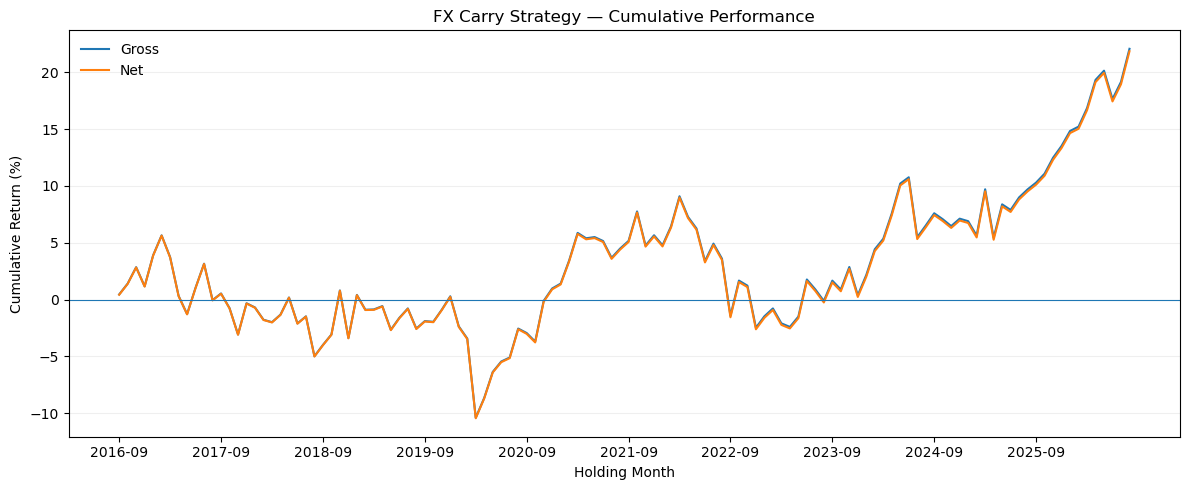

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    backtest["holding_month"].astype(str),
    backtest["cumulative_gross"] * 100,
    label="Gross"
)

plt.plot(
    backtest["holding_month"].astype(str),
    backtest["cumulative_net"] * 100,
    label="Net"
)

plt.axhline(0, linewidth=0.8)

plt.title("FX Carry Strategy — Cumulative Performance")
plt.xlabel("Holding Month")
plt.ylabel("Cumulative Return (%)")

plt.xticks(
    range(0, len(backtest), 12),
    backtest["holding_month"].astype(str).iloc[::12],
    rotation=0
)

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

Maximum drawdown: -0.15200670674945227


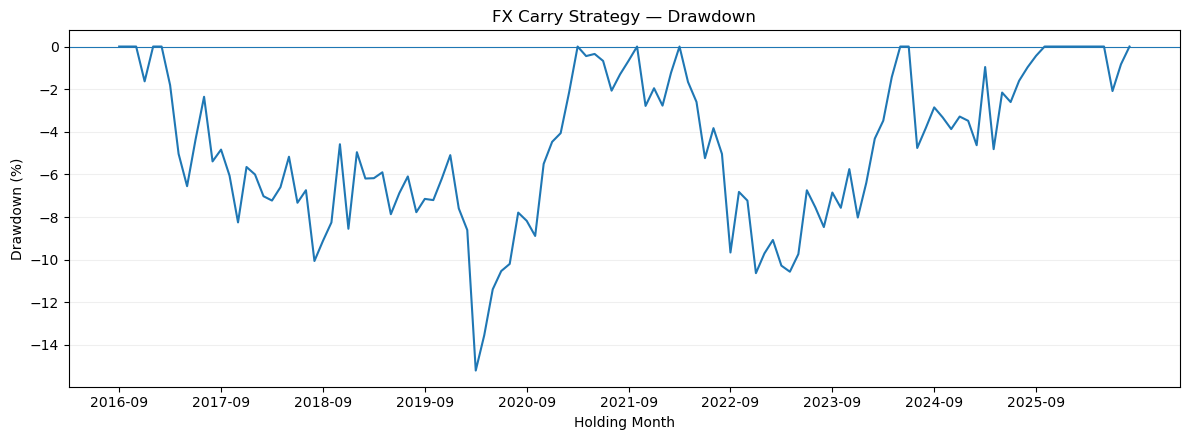

In [38]:
backtest["wealth_net"] = (1 + backtest["long_short_net"]).cumprod()

backtest["running_max"] = backtest["wealth_net"].cummax()

backtest["drawdown"] = backtest["wealth_net"] / backtest["running_max"] - 1

print("Maximum drawdown:", backtest["drawdown"].min())

plt.figure(figsize=(12, 4.5))

plt.plot(
    backtest["holding_month"].astype(str),
    backtest["drawdown"] * 100
)

plt.axhline(0, linewidth=0.8)

plt.title("FX Carry Strategy — Drawdown")
plt.xlabel("Holding Month")
plt.ylabel("Drawdown (%)")

plt.xticks(
    range(0, len(backtest), 12),
    backtest["holding_month"].astype(str).iloc[::12]
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

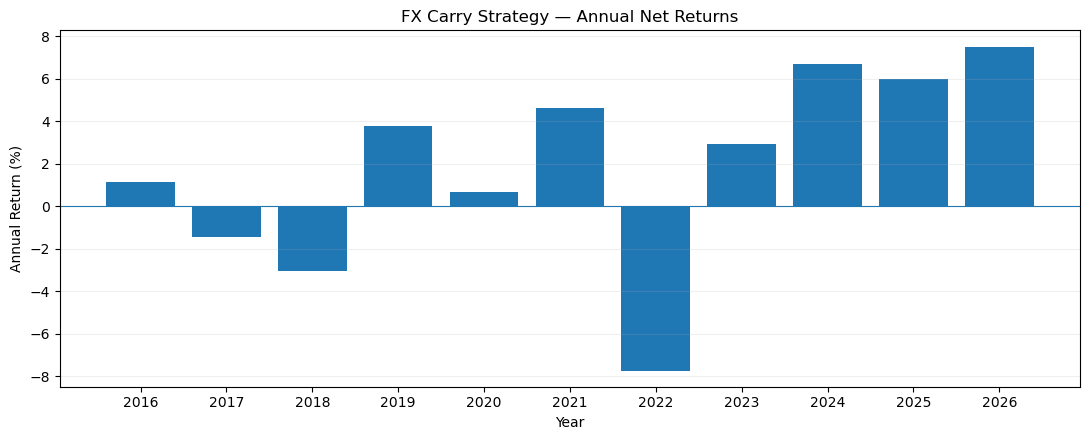

year
2016    0.011459
2017   -0.014738
2018   -0.030722
2019    0.037772
2020    0.006593
2021    0.046092
2022   -0.077335
2023    0.029203
2024    0.067049
2025    0.059593
2026    0.075079


In [39]:
annual_returns = backtest.copy()

annual_returns["year"] = annual_returns["holding_month"].dt.year

annual_returns = annual_returns.groupby("year")["long_short_net"].apply(
    lambda x: (1 + x).prod() - 1
)

plt.figure(figsize=(11, 4.5))

plt.bar(
    annual_returns.index.astype(str),
    annual_returns.values * 100
)

plt.axhline(0, linewidth=0.8)

plt.title("FX Carry Strategy — Annual Net Returns")
plt.xlabel("Year")
plt.ylabel("Annual Return (%)")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print(annual_returns.to_string())

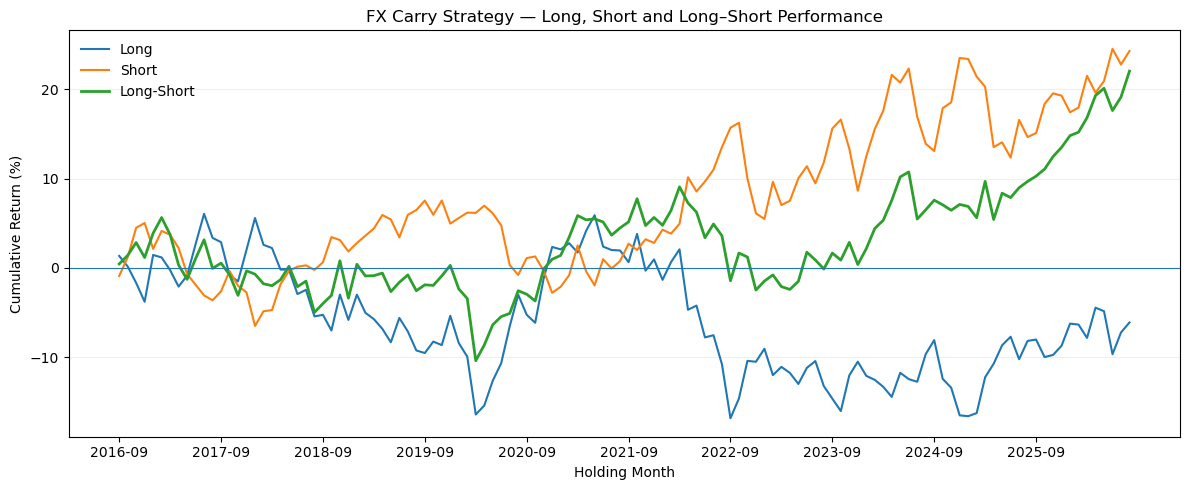

In [40]:
long_short_cum = pd.DataFrame({
    "month": backtest["holding_month"],
    "Long": (1 + backtest["long_total"]).cumprod() - 1,
    "Short": (1 - backtest["short_total"]).cumprod() - 1,
    "Long-Short": (1 + backtest["long_short_gross"]).cumprod() - 1
})

plt.figure(figsize=(12, 5))

plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Long"] * 100,
    label="Long"
)

plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Short"] * 100,
    label="Short"
)

plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Long-Short"] * 100,
    label="Long-Short",
    linewidth=2
)

plt.axhline(0, linewidth=0.8)

plt.title("FX Carry Strategy — Long, Short and Long–Short Performance")
plt.xlabel("Holding Month")
plt.ylabel("Cumulative Return (%)")

plt.xticks(
    range(0, len(long_short_cum), 12),
    long_short_cum["month"].astype(str).iloc[::12]
)

plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

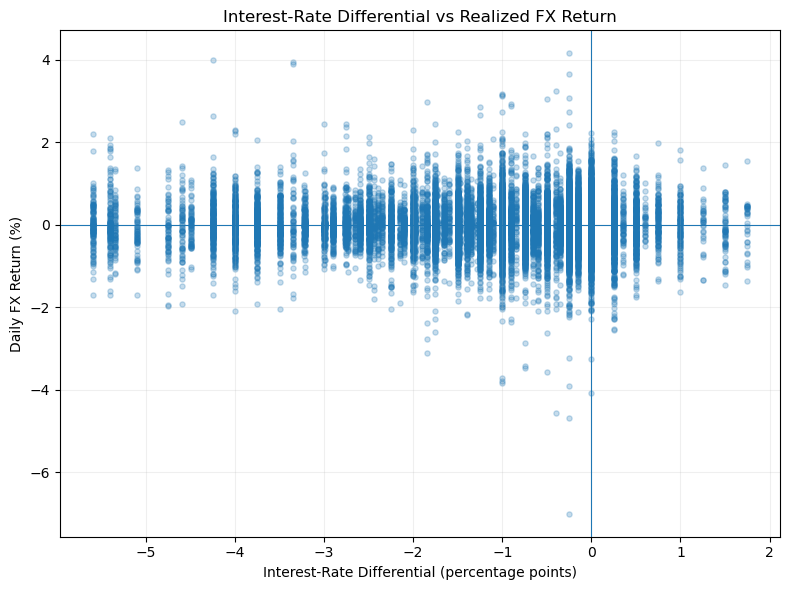

In [41]:
scatter_data = currency_returns[
    ["EUR_diff", "GBP_diff", "JPY_diff", "CHF_diff", "NOK_diff", "AUD_diff", "NZD_diff", "CAD_diff",
     "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
].copy()

x = pd.concat([
    scatter_data[["EUR_diff", "EUR"]].rename(columns={"EUR_diff": "diff", "EUR": "fx_return"}),
    scatter_data[["GBP_diff", "GBP"]].rename(columns={"GBP_diff": "diff", "GBP": "fx_return"}),
    scatter_data[["JPY_diff", "JPY"]].rename(columns={"JPY_diff": "diff", "JPY": "fx_return"}),
    scatter_data[["CHF_diff", "CHF"]].rename(columns={"CHF_diff": "diff", "CHF": "fx_return"}),
    scatter_data[["NOK_diff", "NOK"]].rename(columns={"NOK_diff": "diff", "NOK": "fx_return"}),
    scatter_data[["AUD_diff", "AUD"]].rename(columns={"AUD_diff": "diff", "AUD": "fx_return"}),
    scatter_data[["NZD_diff", "NZD"]].rename(columns={"NZD_diff": "diff", "NZD": "fx_return"}),
    scatter_data[["CAD_diff", "CAD"]].rename(columns={"CAD_diff": "diff", "CAD": "fx_return"})
], ignore_index=True).dropna()

plt.figure(figsize=(8, 6))

plt.scatter(
    x["diff"],
    x["fx_return"] * 100,
    alpha=0.25,
    s=14
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.title("Interest-Rate Differential vs Realized FX Return")
plt.xlabel("Interest-Rate Differential (percentage points)")
plt.ylabel("Daily FX Return (%)")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

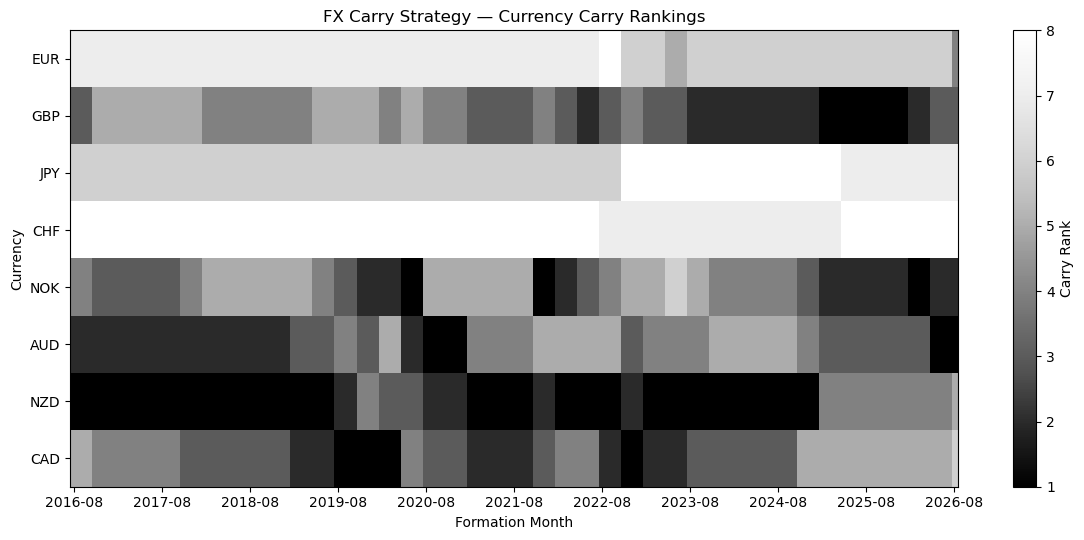

In [42]:
import matplotlib.pyplot as plt

rank_matrix = monthly_ranks.set_index("month")[
    ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
]

plt.figure(figsize=(12, 5.5))

plt.imshow(
    rank_matrix.T,
    aspect="auto",
    interpolation="nearest",
    cmap="Greys_r",
    vmin=1,
    vmax=8
)

plt.colorbar(label="Carry Rank")

plt.title("FX Carry Strategy — Currency Carry Rankings")
plt.xlabel("Formation Month")
plt.ylabel("Currency")

plt.yticks(
    range(len(rank_matrix.columns)),
    rank_matrix.columns
)

plt.xticks(
    range(0, len(rank_matrix), 12),
    rank_matrix.index.astype(str)[::12]
)

plt.tight_layout()
plt.show()

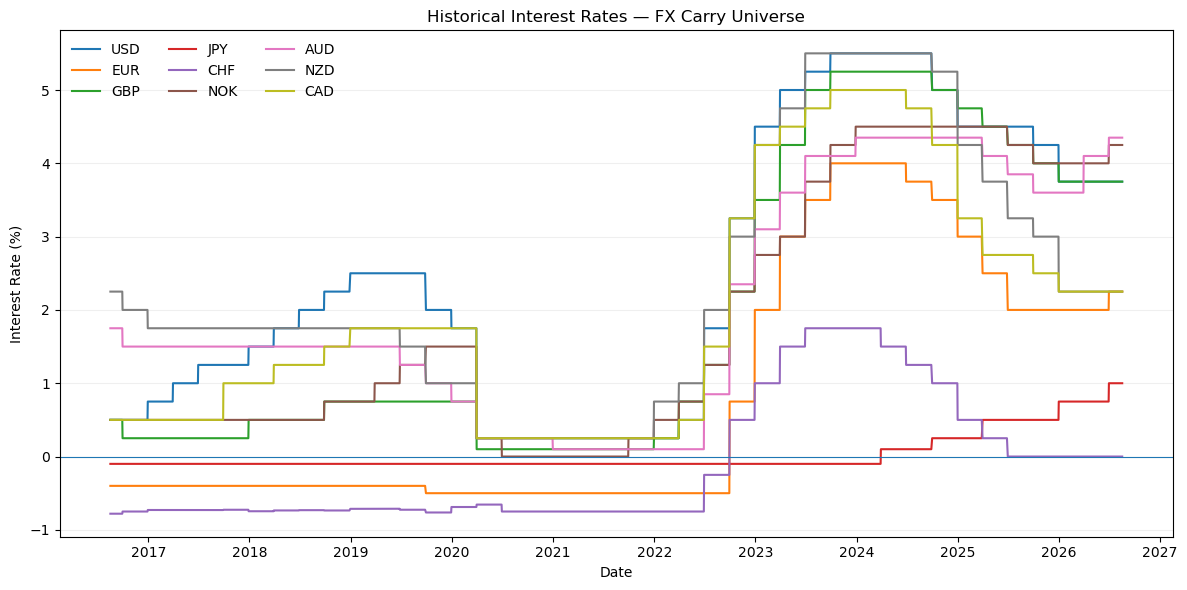

In [43]:
plt.figure(figsize=(12, 6))

for currency in ["USD", "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    plt.plot(
        rate_daily["date"],
        rate_daily[currency.lower() + "_ir"],
        label=currency
    )

plt.axhline(0, linewidth=0.8)

plt.title("Historical Interest Rates — FX Carry Universe")
plt.xlabel("Date")
plt.ylabel("Interest Rate (%)")

plt.legend(
    frameon=False,
    ncol=3
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [45]:
long_currencies = pd.concat([
    backtest["long_1"],
    backtest["long_2"]
]).value_counts()

short_currencies = pd.concat([
    backtest["short_1"],
    backtest["short_2"]
]).value_counts()

high_yielders = monthly_ranks.drop(columns="month").idxmax(axis=1).value_counts()
low_yielders = monthly_ranks.drop(columns="month").idxmin(axis=1).value_counts()

summary = pd.DataFrame({
    "High_Yielder_Count": high_yielders,
    "Low_Yielder_Count": low_yielders,
    "Long_Count": long_currencies,
    "Short_Count": short_currencies
}).fillna(0).astype(int)

summary["Both_Long_and_Short"] = (
    (summary["Long_Count"] > 0) &
    (summary["Short_Count"] > 0)
)

summary = summary.sort_values(
    "High_Yielder_Count",
    ascending=False
)

summary

,High_Yielder_Count,Low_Yielder_Count,Long_Count,Short_Count,Both_Long_and_Short
CHF,88,0,0,120,False
JPY,30,0,0,45,False
EUR,3,0,0,75,False
AUD,0,10,42,0,False
CAD,0,12,36,0,False
GBP,0,12,36,0,False
NOK,0,9,33,0,False
NZD,0,78,93,0,False


Long high-yield currencies:

EUR/USD → long EUR
GBP/USD → long GBP
AUD/USD → long AUD
NZD/USD → long NZD
USD/CAD → long CAD
USD/NOK → long NOK

Short low-yield currencies:

USD/JPY → short JPY
USD/CHF → short CHF

In [48]:
import os
charts_path = "/Users/partha/Documents/FX Carry/outputs/charts"
tables_path = "/Users/partha/Documents/FX Carry/outputs/tables"

os.makedirs(charts_path, exist_ok=True)
os.makedirs(tables_path, exist_ok=True)

rate_daily.to_csv(f"{tables_path}/rate_daily.csv", index=False)
currency_returns.to_csv(f"{tables_path}/currency_returns.csv", index=False)
currency_carry.to_csv(f"{tables_path}/currency_carry.csv", index=False)
monthly_ranks.to_csv(f"{tables_path}/monthly_ranks.csv", index=False)
monthly_positions.to_csv(f"{tables_path}/monthly_positions.csv", index=False)
monthly_returns.to_csv(f"{tables_path}/monthly_returns.csv", index=False)
backtest.to_csv(f"{tables_path}/backtest.csv", index=False)
rate_monthly.to_csv(f"{tables_path}/rate_monthly.csv", index=False)

for currency, df in interest_rates.items():
    df.to_csv(f"{tables_path}/{currency}_interest_rate.csv", index=False)

for pair, df in frd_cleaned.items():
    df.to_csv(f"{tables_path}/frd_{pair}.csv", index=False)

backtest["wealth_net"] = (1 + backtest["long_short_net"]).cumprod()
backtest["running_max"] = backtest["wealth_net"].cummax()
backtest["drawdown"] = backtest["wealth_net"] / backtest["running_max"] - 1

plt.figure(figsize=(12, 5))
plt.plot(
    backtest["holding_month"].astype(str),
    backtest["cumulative_gross"] * 100,
    label="Gross"
)
plt.plot(
    backtest["holding_month"].astype(str),
    backtest["cumulative_net"] * 100,
    label="Net"
)
plt.axhline(0, linewidth=0.8)
plt.title("FX Carry Strategy — Cumulative Performance")
plt.xlabel("Holding Month")
plt.ylabel("Cumulative Return (%)")
plt.xticks(
    range(0, len(backtest), 12),
    backtest["holding_month"].astype(str).iloc[::12]
)
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/01_cumulative_performance.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(12, 4.5))
plt.plot(
    backtest["holding_month"].astype(str),
    backtest["drawdown"] * 100
)
plt.axhline(0, linewidth=0.8)
plt.title("FX Carry Strategy — Drawdown")
plt.xlabel("Holding Month")
plt.ylabel("Drawdown (%)")
plt.xticks(
    range(0, len(backtest), 12),
    backtest["holding_month"].astype(str).iloc[::12]
)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/02_drawdown.png", dpi=300, bbox_inches="tight")
plt.close()

annual_returns = backtest.groupby(
    backtest["holding_month"].dt.year
)["long_short_net"].apply(lambda x: (1 + x).prod() - 1)

annual_returns.to_csv(
    f"{tables_path}/annual_returns.csv",
    header=["annual_net_return"]
)

plt.figure(figsize=(11, 4.5))
plt.bar(
    annual_returns.index.astype(str),
    annual_returns.values * 100
)
plt.axhline(0, linewidth=0.8)
plt.title("FX Carry Strategy — Annual Net Returns")
plt.xlabel("Year")
plt.ylabel("Annual Return (%)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/03_annual_returns.png", dpi=300, bbox_inches="tight")
plt.close()

long_short_cum = pd.DataFrame({
    "month": backtest["holding_month"],
    "Long": (1 + backtest["long_total"]).cumprod() - 1,
    "Short": (1 - backtest["short_total"]).cumprod() - 1,
    "Long-Short": (1 + backtest["long_short_gross"]).cumprod() - 1
})

long_short_cum.to_csv(
    f"{tables_path}/long_short_cumulative.csv",
    index=False
)

plt.figure(figsize=(12, 5))
plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Long"] * 100,
    label="Long"
)
plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Short"] * 100,
    label="Short"
)
plt.plot(
    long_short_cum["month"].astype(str),
    long_short_cum["Long-Short"] * 100,
    label="Long-Short",
    linewidth=2
)
plt.axhline(0, linewidth=0.8)
plt.title("FX Carry Strategy — Long, Short and Long–Short Performance")
plt.xlabel("Holding Month")
plt.ylabel("Cumulative Return (%)")
plt.xticks(
    range(0, len(long_short_cum), 12),
    long_short_cum["month"].astype(str).iloc[::12]
)
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/04_long_short_performance.png", dpi=300, bbox_inches="tight")
plt.close()

scatter_data = currency_returns[
    ["EUR_diff", "GBP_diff", "JPY_diff", "CHF_diff", "NOK_diff", "AUD_diff", "NZD_diff", "CAD_diff",
     "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
].copy()

scatter_data = pd.concat([
    scatter_data[["EUR_diff", "EUR"]].rename(columns={"EUR_diff": "diff", "EUR": "fx_return"}),
    scatter_data[["GBP_diff", "GBP"]].rename(columns={"GBP_diff": "diff", "GBP": "fx_return"}),
    scatter_data[["JPY_diff", "JPY"]].rename(columns={"JPY_diff": "diff", "JPY": "fx_return"}),
    scatter_data[["CHF_diff", "CHF"]].rename(columns={"CHF_diff": "diff", "CHF": "fx_return"}),
    scatter_data[["NOK_diff", "NOK"]].rename(columns={"NOK_diff": "diff", "NOK": "fx_return"}),
    scatter_data[["AUD_diff", "AUD"]].rename(columns={"AUD_diff": "diff", "AUD": "fx_return"}),
    scatter_data[["NZD_diff", "NZD"]].rename(columns={"NZD_diff": "diff", "NZD": "fx_return"}),
    scatter_data[["CAD_diff", "CAD"]].rename(columns={"CAD_diff": "diff", "CAD": "fx_return"})
], ignore_index=True).dropna()

scatter_data.to_csv(
    f"{tables_path}/rate_differential_fx_returns.csv",
    index=False
)

plt.figure(figsize=(8, 6))
plt.scatter(
    scatter_data["diff"],
    scatter_data["fx_return"] * 100,
    alpha=0.25,
    s=14
)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.title("Interest-Rate Differential vs Realized FX Return")
plt.xlabel("Interest-Rate Differential (percentage points)")
plt.ylabel("Daily FX Return (%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/05_rate_differential_vs_fx_return.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(12, 6))

for currency in ["USD", "EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]:
    plt.plot(
        rate_daily["date"],
        rate_daily[currency.lower() + "_ir"],
        label=currency
    )

plt.axhline(0, linewidth=0.8)
plt.title("Historical Interest Rates — FX Carry Universe")
plt.xlabel("Date")
plt.ylabel("Interest Rate (%)")
plt.legend(frameon=False, ncol=3)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(f"{charts_path}/06_historical_interest_rates.png", dpi=300, bbox_inches="tight")
plt.close()

rank_matrix = monthly_ranks.set_index("month")[
    ["EUR", "GBP", "JPY", "CHF", "NOK", "AUD", "NZD", "CAD"]
]

plt.figure(figsize=(12, 5.5))
plt.imshow(
    rank_matrix.T,
    aspect="auto",
    interpolation="nearest",
    cmap="Greys_r",
    vmin=1,
    vmax=8
)
plt.colorbar(label="Carry Rank")
plt.title("FX Carry Strategy — Currency Carry Rankings")
plt.xlabel("Formation Month")
plt.ylabel("Currency")
plt.yticks(
    range(len(rank_matrix.columns)),
    rank_matrix.columns
)
plt.xticks(
    range(0, len(rank_matrix), 12),
    rank_matrix.index.astype(str)[::12]
)
plt.tight_layout()
plt.savefig(f"{charts_path}/07_currency_carry_rankings.png", dpi=300, bbox_inches="tight")
plt.close()

print("Charts saved:", len(os.listdir(charts_path)))
print("Tables saved:", len(os.listdir(tables_path)))

Charts saved: 7
Tables saved: 28
